In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import json
import os
import numpy as np
import torch
import torchvision.utils as vutils
import pandas as pd
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import euclidean_distances
import itertools
import scipy
import nimfa

# from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils
from compcats.datasets.fmri.utils import nsd_ds_utils

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR

coco_train_annotations = COCO(paths.COCO_TRAIN_ANNOTATIONS_PATH)
coco_train_captions = COCO(paths.COCO_TRAIN_CAPTIONS_PATH)
coco_val_annotations = COCO(paths.COCO_VAL_ANNOTATIONS_PATH)
coco_val_captions = COCO(paths.COCO_VAL_CAPTIONS_PATH)

import warnings
warnings.filterwarnings(
    "ignore",
    message=".*invalid value encountered in scalar divide.*",
    category=RuntimeWarning
)
warnings.filterwarnings(
    "ignore",
    message=".*invalid value encountered in multiply.*",
    category=RuntimeWarning
)
warnings.filterwarnings(
    "ignore",
    message=".*divide by zero encountered in scalar.*",
    category=RuntimeWarning
)

Font name from TTC: Avenir
Style: Book
loading annotations into memory...
Done (t=8.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.56s)
creating index...
index created!
loading annotations into memory...
Done (t=0.34s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


In [2]:
# Utils

def get_image_labels(image_id, annotations_obj, captions_obj):
    """
    Get the labels for an image given its ID from the COCO dataset.
    
    Args:
        image_id (int): The ID of the image.
        
    Returns:
        list: A list of labels (category names) associated with the image.
    """
    # Get all annotations for the given image
    annotation_ids = annotations_obj.getAnnIds(imgIds=image_id)
    annotations = annotations_obj.loadAnns(annotation_ids)
    # Get category IDs from annotations
    category_ids = {annotation['category_id'] for annotation in annotations}
    # Get category names from category IDs
    category_names = [annotations_obj.loadCats(cat_id)[0]['name'] for cat_id in category_ids]

    # Get captions for the image
    caption_ids = captions_obj.getAnnIds(imgIds=image_id)
    captions = captions_obj.loadAnns(caption_ids)
    caption_texts = [caption['caption'] for caption in captions]
    
    return category_names, caption_texts

def add_image_info_to_df(df):
    """
    Add labels to the DataFrame given the COCO object.
    
    Args:
        df (pd.DataFrame): The DataFrame to which to add the labels.
        
    Returns:
        pd.DataFrame: The DataFrame with the labels added.
    """
    # Create a copy of the dataframe to avoid the SettingWithCopyWarning
    df_copy = df.copy()
    
    # Create a function to get the appropriate COCO object based on the split
    def get_annotations_obj(split):
        if split == 'train2017':
            return coco_train_annotations
        else:
            return coco_val_annotations
    def get_captions_obj(split):
        if split == 'train2017':
            return coco_train_captions
        else:
            return coco_val_captions
        
    # Apply the function to get labels for each row using the appropriate COCO object
    df_copy.loc[:, 'labels'] = df_copy.apply(
        lambda row: get_image_labels(
            row['cocoId'], 
            annotations_obj=get_annotations_obj(row['cocoSplit']), 
            captions_obj=get_captions_obj(row['cocoSplit'])
        )[0],
        axis=1
    )
    df_copy.loc[:, 'captions'] = df_copy.apply(
        lambda row: get_image_labels(
            row['cocoId'], 
            annotations_obj=get_annotations_obj(row['cocoSplit']), 
            captions_obj=get_captions_obj(row['cocoSplit'])
        )[1], 
        axis=1
    )
    return df_copy

In [3]:
# NMF Utils

np.mat = np.asmatrix  # patch removed np.mat to use np.asmatrix

def estimate_bic(V, W, H):
    """
    Estimate the Bayesian Information Criterion (BIC) for the NMF decomposition.
    V = W @ H
    
    Args:
        V (np.ndarray): The original data matrix of shape (n_features, n_samples).
        W (np.ndarray): The matrix of shape (n_features, n_components) representing the coefficients.
        H (np.ndarray): The matrix of shape (n_components, n_samples) representing the components.
        
    Returns:
        float: The estimated BIC value.
    """
    # Reconstruction
    V_hat = np.dot(W, H)

    # ===========================
    # 2. Compute BIC (Gaussian likelihood)
    # ===========================
    m, n = V.shape
    p = W.size + H.size   # number of parameters

    # Residuals
    residuals = V - V_hat
    sigma2 = np.mean(residuals**2)

    # Log-likelihood under Gaussian assumption
    logL = -0.5 * m * n * np.log(2 * np.pi * sigma2) - 0.5 * np.sum(residuals**2) / sigma2

    # Bayesian Information Criterion
    BIC = -2 * logL + p * np.log(m * n)
    
    return BIC

def get_nmf_decomposed_data(data, n_runs=50, n_components=10, random_state=0):
    """
    Perform Non-negative Matrix Factorization (NMF) on the given data.
    
    Args:
        data (np.ndarray or torch.Tensor): The input data matrix of shape (n_samples, n_features).
        n_iter (int): The number of iterations for the NMF algorithm.
        n_components (int): The number of components to extract.
        random_state (int): Random seed for reproducibility.
        
    Returns:
        W (np.ndarray): The matrix of shape (n_samples, n_components) representing the coefficients.
        H (np.ndarray): The matrix of shape (n_components, n_features) representing the components.
    """
    ### Perform baseline shift to make all entries non-negative
    V = (data - data.min(0)).T
    
    ### Run 50 iterations of the Bayesian NMF algorithm
    
    W, H, data_transformed = None, None, None
    metrics = []
    for r_ in range(n_runs):
        bdnmf = nimfa.Bd(V, seed="random_c", rank=n_components, max_iter=12, alpha=np.zeros((V.shape[0], n_components)),
          beta=np.zeros((n_components, V.shape[1])), theta=.0, k=.0, sigma=1., skip=100, stride=1,
          n_w=np.zeros((n_components, 1)), n_h=np.zeros((n_components, 1)), n_run = 1, n_sigma=False) 
        bdnmf_fit = bdnmf()

        W = np.asarray(bdnmf_fit.basis()).copy()
        H = np.asarray(bdnmf_fit.coef()).copy()
        bic = estimate_bic(V, W, H)
        data_transformed = np.asarray(H.T).copy()

        metrics.append({
            'n_components': n_components,
            'run': r_,
            'bic': bic,
            'rss': bdnmf_fit.fit.rss(),
            'evar': bdnmf_fit.fit.evar(),
            'kl': bdnmf_fit.distance(metric='kl'),
            'sparseness_W': bdnmf_fit.fit.sparseness()[0],
            'sparseness_H': bdnmf_fit.fit.sparseness()[1]
        })
    metrics_df = pd.DataFrame(metrics)
    return W, H, data_transformed, metrics_df

# Dev: FFA, s1 - rn50 imagenet 

## Top images

In [4]:
# Variabes
subject = 1
froi = 'FFA'
tthreshold = 7

model_name = 'resnet50imagenet1kv2'
layer = ma.get_froi_models_layers(froi, froi)[model_name]
model = ma.get_model(model_name)

shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)

In [ ]:
# Get subject data
subject_data, images_df = nsd.get_betas(
    NSD_DIR, subject, froi, tthreshold, voxels=True
)
# Add COCO labels to images_df
images_df = add_image_info_to_df(images_df)
# Filter out nsdIds that are in stim1000_nsdids
subject_images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
subject_nsdids = subject_images_df['nsdId'].values
# Get stimuli
nsdcoco_stim = nsd.get_stimuli_dataset(
    NSD_DIR, transform=None, subset=None
).all_stimuli
stimuli = nsdcoco_stim[subject_nsdids]
stimuli = torch.tensor(stimuli)
# Get model data
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, froi_localizer='grillspector',
    froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR
)
model_data = model_data[subject_nsdids]

# Expected shapes
# subject_data: (num_images, num_voxels)
# model_data: (num_images, num_features)
# stimuli: (num_images, height, width, channels)
print("Subject data shape:", subject_data.shape)
print("Model data shape:", model_data.shape)
print("Stimuli shape:", stimuli.shape)

n_samples = subject_data.shape[0]
print("Number of samples:", n_samples)


Subject data shape: torch.Size([9000, 156])
Model data shape: torch.Size([9000, 729])
Stimuli shape: torch.Size([9000, 425, 425, 3])
Number of samples: 9000


In [ ]:
# Plot top 100 images for subject and fROI
subject_data_unitmean = subject_data.mean(axis=-1)
model_data_unitmean = model_data.mean(axis=-1)
# Get top 100 indices
top100_subject_indices = np.argsort(subject_data_unitmean.cpu().numpy())[n_samples-100:]
top100_subject_indices = top100_subject_indices[::-1].copy()
top100_model_indices = np.argsort(model_data_unitmean.cpu().numpy())[n_samples-100:]
top100_model_indices = top100_model_indices[::-1].copy()

# Plot the top 100 images for the subject using torchvision grid
# Subject top 100
top100_subject_images = stimuli[top100_subject_indices]
top100_subject_images_tensor = top100_subject_images.permute(0, 3, 1, 2).float() # Convert to (N, C, H, W)
grid_subject = vutils.make_grid(top100_subject_images_tensor, nrow=10, padding=2, normalize=True)
plt.figure(figsize=(15, 15))
plt.imshow(grid_subject.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
plt.axis('off')
plt.title(f'Top 100 Images for Subject {subject} in {froi} (by fMRI response)', fontsize=16)
plt.show()
# Model top 100
top100_model_images = stimuli[top100_model_indices]
top100_model_images_tensor = top100_model_images.permute(0, 3, 1, 2).float()  # Convert to (N, C, H, W)
grid_model = vutils.make_grid(top100_model_images_tensor, nrow=10, padding=2, normalize=True)
plt.figure(figsize=(15, 15))
plt.imshow(grid_model.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
plt.axis('off')
plt.title(f'Top 100 Images for Model {model_name} Layer {layer} (by Model response)', fontsize=16)
plt.show()

## NMF

### Number of components

In [ ]:
n_runs = 10
N_components = [1, 2, 3, 4, 5]
result_dfs = []
bics = []

for n_components in N_components:
    print(f"Running NMF with n_components={n_components}")
    w, h, subject_data_nmf, nmf_metrics_df = get_nmf_decomposed_data(subject_data.cpu().numpy(), n_runs=n_runs, n_components=n_components)
    result_dfs.append(nmf_metrics_df)
    bics.append(nmf_metrics_df['bic'].tolist())

# Plot BIC vs. number of components with error bars
plt.figure(figsize=(8, 6))
# Calculate means and standard deviations
bic_medians = [np.median(bic) for bic in bics]
bic_stds = [np.std(bic) for bic in bics]
plt.errorbar(N_components, bic_medians, yerr=bic_stds, fmt='o-', capsize=5)
plt.xlabel('Number of Components', fontsize=14)
plt.ylabel('BIC', fontsize=14)
plt.title(f'BIC vs. Number of Components for Subject {subject} {froi} (t>{tthreshold})', fontsize=16)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.xticks(N_components, N_components)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/nmf_bic_subject{subject}_{froi}.png', dpi=300)
plt.show()
plt.close()

metric_names = ['rss', 'evar', 'kl', 'sparseness_W', 'sparseness_H']

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for i, metric in enumerate(metric_names):
    df = result_dfs.copy()
    metric_medians = [df[n-1][metric].median() for n in N_components]
    metric_stds = [df[n-1][metric].std() for n in N_components]
    ax[i].errorbar(N_components, metric_medians, yerr=metric_stds, fmt='o-', capsize=5)
    ax[i].set_xlabel('Number of Components', fontsize=12)
    ax[i].set_title(metric, fontsize=14)
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['left'].set_position(('outward', 5))
    ax[i].spines['bottom'].set_position(('outward', 5))
    ax[i].set_xticks(N_components)
plt.suptitle(f'BIC vs. Number of Components for Subject {subject} {froi} (t>{tthreshold})', fontsize=16)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/nmf_metrics_subject{subject}_{froi}.png', dpi=300)
plt.show()
plt.close()

In [ ]:
n_runs = 10
N_components = [1, 2, 3, 4, 5]
result_dfs = []
bics = []

for n_components in N_components:
    print(f"Running NMF with n_components={n_components}")
    w, h, model_data_nmf, nmf_metrics_df = get_nmf_decomposed_data(model_data.cpu().numpy(), n_runs=n_runs, n_components=n_components)
    result_dfs.append(nmf_metrics_df)
    bics.append(nmf_metrics_df['bic'].tolist())

# Plot BIC vs. number of components with error bars
plt.figure(figsize=(8, 6))
# Calculate means and standard deviations
bic_medians = [np.median(bic) for bic in bics]
bic_stds = [np.std(bic) for bic in bics]
plt.errorbar(N_components, bic_medians, yerr=bic_stds, fmt='o-', capsize=5)
plt.xlabel('Number of Components', fontsize=14)
plt.ylabel('BIC', fontsize=14)
plt.title(f'BIC vs. Number of Components for model {model_name} in {layer} {froi} (t>{tthreshold})', fontsize=16)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.xticks(N_components, N_components)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/nmf_bic_subject{subject}_{froi}.png', dpi=300)
plt.show()
plt.close()

metric_names = ['rss', 'evar', 'kl', 'sparseness_W', 'sparseness_H']

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for i, metric in enumerate(metric_names):
    df = result_dfs.copy()
    metric_medians = [df[n-1][metric].median() for n in N_components]
    metric_stds = [df[n-1][metric].std() for n in N_components]
    ax[i].errorbar(N_components, metric_medians, yerr=metric_stds, fmt='o-', capsize=5)
    ax[i].set_xlabel('Number of Components', fontsize=12)
    ax[i].set_title(metric, fontsize=14)
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['left'].set_position(('outward', 5))
    ax[i].spines['bottom'].set_position(('outward', 5))
    ax[i].set_xticks(N_components)
plt.suptitle(f'NMF Metrics vs. Number of Components for model {model_name} in {layer} {froi} (t>{tthreshold})', fontsize=16)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/nmf_metrics_subject{subject}_{froi}.png', dpi=300)
plt.show()
plt.close()

### Interpreting the components

In [46]:
ffa7_n_components = {
    's1': 5, # 2
    'resnet50imagenet1kv2': 5 # 3
}

In [47]:
s1_w, s1_h, s1_nmf, s1_metrics_df = get_nmf_decomposed_data(subject_data.cpu().numpy(), n_runs=n_runs, n_components=ffa7_n_components['s1'])
rn50_w, rn50_h, rn50_nmf, rn50_metrics_df = get_nmf_decomposed_data(model_data.cpu().numpy(), n_runs=n_runs, n_components=ffa7_n_components['resnet50imagenet1kv2'])

In [48]:
s1_transformed_df = pd.DataFrame(s1_nmf, columns=[f'component_{i+1}' for i in range(ffa7_n_components['s1'])])
s1_transformed_df['nsdId'] = subject_images_df['nsdId']
rn50_transformed_df = pd.DataFrame(rn50_nmf, columns=[f'component_{i+1}' for i in range(ffa7_n_components['resnet50imagenet1kv2'])])
rn50_transformed_df['nsdId'] = subject_images_df['nsdId']

In [ ]:
systems_info = {
    's1': s1_transformed_df,
    'resnet50imagenet1kv2': rn50_transformed_df
}

# Plot top 25 images for each component using torchvision grid
n_top = 25

for system_name, components_df in systems_info.items():
    n_components = ffa7_n_components[system_name]

    fig, axes = plt.subplots(1, n_components, figsize=(12 * n_components, 12))
    if n_components == 1:
        axes = [axes]

    for comp_idx in range(n_components):
        component_name = f'component_{comp_idx + 1}'
        
        # Get top 25 indices for this component
        top_indices = components_df.nlargest(n_top, component_name).index
        # top_nsdids = s1_transformed_df.loc[top_indices, 'nsdId'].values
        
        # Get corresponding images
        # Find indices in subject_nsdids that match top_nsdids
        # image_indices = [np.where(subject_nsdids == nsdid)[0][0] for nsdid in top_nsdids]
        top_images = stimuli[top_indices]
        
        # Convert to tensor format for grid
        top_images_tensor = top_images.permute(0, 3, 1, 2).float()  # Convert to (N, C, H, W)
        grid = vutils.make_grid(top_images_tensor, nrow=5, padding=2, normalize=True)
        
        # Plot
        axes[comp_idx].imshow(grid.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
        axes[comp_idx].axis('off')
        axes[comp_idx].set_title(f'Top {n_top} Images for {system_name} {froi} Component {comp_idx + 1}', fontsize=14)

    plt.tight_layout()
    plt.show()

## Trial: 5 components for all

In [12]:
def nmf_analysis(
    subject, model_name, froi, tthreshold, n_runs=1, n_components=5
):
    layer = ma.get_froi_models_layers(froi, froi)[model_name]
    model = ma.get_model(model_name)

    shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)

    print(f"Running NMF analysis for subject {subject}, model {model_name}, froi {froi}, t>{tthreshold}, n_runs={n_runs}, n_components={n_components}")
    print('Getting data...')
    # Get subject data
    subject_data, images_df = nsd.get_betas(
        NSD_DIR, subject, froi, tthreshold, voxels=True
    )
    # Add COCO labels to images_df
    images_df = add_image_info_to_df(images_df)
    # Filter out nsdIds that are in stim1000_nsdids
    subject_images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
    subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
    subject_nsdids = subject_images_df['nsdId'].values
    # Get stimuli
    nsdcoco_stim = nsd.get_stimuli_dataset(
        NSD_DIR, transform=None, subset=None
    ).all_stimuli
    stimuli = nsdcoco_stim[subject_nsdids]
    stimuli = torch.tensor(stimuli)
    # Get model data
    model_data = model_utils.get_dataset_activations(
        MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, froi_localizer='grillspector',
        froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR
    )
    model_data = model_data[subject_nsdids]
    print('Data retrival complete')

    # Expected shapes
    # subject_data: (num_images, num_voxels)
    # model_data: (num_images, num_features)
    # stimuli: (num_images, height, width, channels)
    print("Subject data shape:", subject_data.shape)
    print("Model data shape:", model_data.shape)
    print("Stimuli shape:", stimuli.shape)

    n_samples = subject_data.shape[0]
    print("Number of samples:", n_samples)
    
    # NMF
    print('Running NMF...')
    subject_w, subject_h, subject_nmf, subject_metrics_df = get_nmf_decomposed_data(subject_data.cpu().numpy(), n_runs=n_runs, n_components=n_components)
    model_w, model_h, model_nmf, model_metrics_df = get_nmf_decomposed_data(model_data.cpu().numpy(), n_runs=n_runs, n_components=n_components)
    subject_transformed_df = pd.DataFrame(subject_nmf, columns=[f'component_{i+1}' for i in range(n_components)])
    subject_transformed_df['nsdId'] = subject_images_df['nsdId']
    model_transformed_df = pd.DataFrame(model_nmf, columns=[f'component_{i+1}' for i in range(n_components)])
    model_transformed_df['nsdId'] = subject_images_df['nsdId']
    print('NMF complete')

    systems_info = {
        f'subject {subject}': subject_transformed_df,
        model_name: model_transformed_df
    }

    # Plot top 25 images for each component using torchvision grid
    n_top = 25

    for system_name, components_df in systems_info.items():
        fig, axes = plt.subplots(1, n_components, figsize=(12 * n_components, 12))
        if n_components == 1:
            axes = [axes]

        for comp_idx in range(n_components):
            component_name = f'component_{comp_idx + 1}'
            
            # Get top 25 indices for this component
            top_indices = components_df.nlargest(n_top, component_name).index
            
            # Get corresponding images
            top_images = stimuli[top_indices]
            
            # Convert to tensor format for grid
            top_images_tensor = top_images.permute(0, 3, 1, 2).float()  # Convert to (N, C, H, W)
            grid = vutils.make_grid(top_images_tensor, nrow=5, padding=2, normalize=True)
            
            # Plot
            axes[comp_idx].imshow(grid.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
            axes[comp_idx].axis('off')
            axes[comp_idx].set_title(f'Top {n_top} Images for {system_name} {froi} Component {comp_idx + 1}', fontsize=14)

        plt.tight_layout()
        plt.show()

### ResNet50 ImageNet

In [ ]:
nmf_analysis(1, 'resnet50imagenet1kv2', 'FFA', 7, n_runs=1, n_components=5)

In [ ]:
nmf_analysis(1, 'resnet50imagenet1kv2', 'PPA', 7, n_runs=1, n_components=5)

In [ ]:
nmf_analysis(1, 'resnet50imagenet1kv2', 'EBA', 7, n_runs=1, n_components=5)

### ResNet 50 CLIP

In [ ]:
nmf_analysis(1, 'resnet50openaiclip', 'FFA', 7, n_runs=1, n_components=5)

In [ ]:
nmf_analysis(1, 'resnet50openaiclip', 'PPA', 7, n_runs=1, n_components=5)

In [ ]:
nmf_analysis(1, 'resnet50openaiclip', 'EBA', 7, n_runs=1, n_components=5)

# Dev: Consensus across 515 images

## Setup

In [5]:
# Variabes
subjects = [1, 2, 3, 4, 5, 6, 7, 8]
froi = 'FFA'
tthreshold = 7

model_name = 'resnet50imagenet1kv2'
layer = ma.get_froi_models_layers(froi, froi)[model_name]
model = ma.get_model(model_name)

results_dir = f'{RESULTS_DIR}/exploration/nmf/ffa_7'
os.makedirs(results_dir, exist_ok=True)

In [ ]:
# NMF utils with consensus

def get_subject_515_data(subject, froi, tthreshold=7):
    # Get subject data
    subject_data, _ = nsd.get_betas(
        NSD_DIR, subject, froi, tthreshold, voxels=True, subset=515
    )
    subject_data = subject_data.cpu().numpy()
    return subject_data

def get_nmf_decomposed_data(data, n_components, n_runs=50):
    """
    Perform Non-negative Matrix Factorization (NMF) on the given data.
    
    Args:
        data (np.ndarray or torch.Tensor): The input data matrix of shape (n_samples, n_features).
        n_iter (int): The number of iterations for the NMF algorithm.
        n_components (int): The number of components to extract.
        
    Returns:
        W (np.ndarray): The matrix of shape (n_samples, n_components) representing the coefficients.
        H (np.ndarray): The matrix of shape (n_components, n_features) representing the components.
    """
    # nimfa expects the input shape to be (n_features, n_samples)
    ### Perform baseline shift to make all entries non-negative
    V = (data - data.min(0)).T

    ### Run n_runs of the Bayesian NMF algorithm
    W, H = {}, {}
    metrics = []
    for r_ in range(n_runs):
        bdnmf = nimfa.Bd(V, seed="random_c", rank=n_components, max_iter=12, alpha=np.zeros((V.shape[0], n_components)),
            beta=np.zeros((n_components, V.shape[1])), theta=.0, k=.0, sigma=1., skip=100, stride=1,
            n_w=np.zeros((n_components, 1)), n_h=np.zeros((n_components, 1)), n_run = 1, n_sigma=False) 
        bdnmf_fit = bdnmf()
        fit_summary = bdnmf_fit.summary()

        W_run = np.asarray(bdnmf_fit.basis()).copy() # Shape: (n_features, n_components)
        H_run = np.asarray(bdnmf_fit.coef()).copy() # Shape: (n_components, n_samples)
        bic = estimate_bic(V, W_run, H_run)
        # Store results
        W[r_] = W_run
        H[r_] = H_run
        metrics.append({
            'n_components': n_components,
            'run': r_,
            'n_iters': fit_summary['n_iter'],
            'bic': bic,
            'rss': fit_summary['rss'],
            'evar': fit_summary['evar'],
            'kl': fit_summary['kl'],
            'sparseness_W': fit_summary['sparseness'][0],
            'sparseness_H': fit_summary['sparseness'][1]
        })
    metrics_df = pd.DataFrame(metrics)
    return W, H, metrics_df

def get_nmf_consensus_components(H_dict):
    """
    Get consensus components from multiple NMF runs by averaging the H matrices.
    # Consensus sources:
    # https://github.com/mk2299/ComponentModeling/blob/main/get_consensus.py#L9
    # https://github.com/dylkot/cNMF/blob/main/src/cnmf/cnmf.py#L823
    
    Args:
        H_dict (dict): A dictionary where keys are run indices and values are H matrices of shape (n_components, n_samples).
        
    Returns:
        np.ndarray: The consensus H matrix of shape (n_samples, n_components).
    """

    resp = []
    for k, v in H_dict.items():
        resp.append(v)  # Shape: (n_samples, n_components)
    resp = np.asarray(resp)
    resp = resp.reshape(-1, resp.shape[-1])
    total_components = resp.shape[0]

    combined_spectra = pd.DataFrame(resp, columns=range(resp.shape[-1]), index=['run%d' % i for i in range(total_components)])        
    # save_df_to_npz(combined_spectra, '%s/spectra_subj%02d.npz' % (save_dir, subj))
    # merged_spectra = load_df_from_npz('%s/spectra_subj%02d.npz' % (save_dir, subj)) 
    merged_spectra = combined_spectra

    density_threshold = 0.5
    k = n_components
    local_neighborhood_size = 0.30

    n_neighbors = int(local_neighborhood_size * merged_spectra.shape[0]/k)

    # Rescale topics such to length of 1.
    l2_spectra = (merged_spectra.T/np.sqrt((merged_spectra**2).sum(axis=1))).T

    #   first find the full distance matrix
    topics_dist = euclidean_distances(l2_spectra.values)
    #   partition based on the first n neighbors
    partitioning_order  = np.argpartition(topics_dist, n_neighbors+1)[:, :n_neighbors+1]
    #   find the mean over those n_neighbors (excluding self, which has a distance of 0)
    distance_to_nearest_neighbors = topics_dist[np.arange(topics_dist.shape[0])[:, None], partitioning_order]
    local_density = pd.DataFrame(distance_to_nearest_neighbors.sum(1)/(n_neighbors),
                                    columns=['local_density'],
                                    index=l2_spectra.index)

    density_filter = local_density.iloc[:, 0] < density_threshold
    l2_spectra = l2_spectra.loc[density_filter, :]

    kmeans_model = KMeans(n_clusters=k, n_init=10, random_state=1)
    kmeans_model.fit(l2_spectra)
    kmeans_cluster_labels = pd.Series(kmeans_model.labels_+1, index=l2_spectra.index)

    # Find median usage for each gene across cluster
    median_spectra = l2_spectra.groupby(kmeans_cluster_labels).median()

    # Normalize median spectra to probability distributions.
    median_spectra = (median_spectra.T/median_spectra.sum(1)).T

    # Compute the silhouette score
    stability = silhouette_score(l2_spectra.values, kmeans_cluster_labels, metric='euclidean').item()

    #### Final response profile matrix 

    data_transformed = median_spectra.values.T

    return data_transformed, stability

In [ ]:
# Estimate optimal number of NMF components for all subjects
subjects_data = {
    i: get_subject_515_data(i, froi, tthreshold) for i in subjects
}
subjects_nmf_decomposed = {}
n_components_list = [1, 2, 3, 4, 5]
for subject, data in subjects_data.items():
    if subject not in subjects_nmf_decomposed:
        subjects_nmf_decomposed[subject] = {}
    for n_components in n_components_list:
        if n_components not in subjects_nmf_decomposed[subject]:
            subjects_nmf_decomposed[subject][n_components] = {
                'H_dict': None,
                'W_dict': None,
                'metrics_df_dict': None
            }
        nmf_W, nmf_H, nmf_metrics_df = get_nmf_decomposed_data(data, n_components=n_components)
        subjects_nmf_decomposed[subject][n_components]['H_dict'] = nmf_H
        subjects_nmf_decomposed[subject][n_components]['W_dict'] = nmf_W
        subjects_nmf_decomposed[subject][n_components]['metrics_df_dict'] = nmf_metrics_df

# 5 n_components * 8 subjects * 50 runs = 2000 NMF runs

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
component_bic_medians = []
component_bic_sems = []
for subject in subjects:
    subject_bics = []
    for n_components in n_components_list:
        # Get median and SEM of BIC
        metrics_df = subjects_nmf_decomposed[subject][n_components]['metrics_df_dict']
        subject_bics.append(metrics_df['bic'].tolist())
    subject_bics = np.array(subject_bics)
    # Min-Max Normalize the subject_BICs for each subject across n_components
    min_bic, max_bic = subject_bics.min(), subject_bics.max()
    subject_bics = (subject_bics - min_bic) / (max_bic - min_bic)
    subject_bic_medians = subject_bics.mean(axis=1)
    subject_bic_sems = subject_bics.std(axis=1) / np.sqrt(subject_bics.shape[1])
    component_bic_medians.append(subject_bic_medians)
    component_bic_sems.append(subject_bic_sems)
    # Connect the points with a line for each subject
    ax.plot(n_components_list, subject_bic_medians, color='lightgray', alpha=0.6, zorder=1)
# Plot a bix plot of the BICs for each n_components across subjects
component_bic_medians = np.array(component_bic_medians)
component_bic_sems = np.array(component_bic_sems)
ax.boxplot(component_bic_medians, positions=n_components_list, widths=0.6)
# Also plot the true points for each subject, n_components with SEM error bars
x_jitter = np.random.uniform(-0.1, 0.1, size=len(subjects))
for nc_idx, n_components in enumerate(n_components_list):
    ax.errorbar(
        np.array([n_components]*len(subjects))+x_jitter,
        component_bic_medians[:, nc_idx],
        yerr=component_bic_sems[:, nc_idx],
        fmt='o', color='gray', alpha=0.75, zorder=2
    )
ax.set_xlabel('Number of Components', fontsize=14)
ax.set_ylabel('Min-Max scaled BIC', fontsize=14)
ax.set_title(f'BIC vs. Number of Components for {froi} (t>{tthreshold}) across shared 515 stimuli', fontsize=12)
ax.set_ylim((-0.05, 1.05))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(min(n_components_list), max(n_components_list))
ax.spines['left'].set_bounds(0, 1)
ax.set_xticks(n_components_list)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/nmf_bic_all_subjects_{froi}.png', dpi=300)
plt.show()
plt.close()

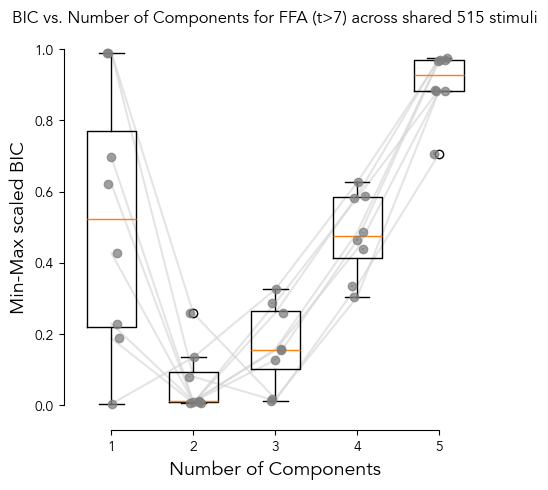

In [ ]:
# Get consensus components for each subject for n_components=2

N_components_ffa = 2
N_subjects = len(subjects)

n_components = N_components_ffa
subject_consensus_components = {}
subject_consensus_stabilities = {}
for subject in subjects:
    subject_consensus_components[subject] = None
    subject_consensus_stabilities[subject] = None
    nmf_H_dict = subjects_nmf_decomposed[subject][n_components]['H_dict']
    consensus_H, stability = get_nmf_consensus_components(nmf_H_dict)
    subject_consensus_components[subject] = consensus_H
    subject_consensus_stabilities[subject] = stability
    print(f"Subject {subject} stability: {stability}")

Subject 1 stability: 0.7568400015855559
Subject 2 stability: 0.7195055564505642
Subject 3 stability: 0.7144493315873717
Subject 4 stability: 0.7431023968601632
Subject 5 stability: 0.7678844960616251
Subject 6 stability: 0.689054752009273
Subject 7 stability: 0.7461733978938985
Subject 8 stability: 0.8060436509375519


In [ ]:
# Find the component combinations that yield the highest inter-subject consistency

# Get all possible combinations of components across subjects and compute average correlation
def subject_average_corr_component_combinations(
    H_dict, n_components=2
):
    combination_avg_corrs = []
    n_subjects = len(H_dict)
    all_possible_combinations = list(itertools.product(range(n_components), repeat=n_subjects))
    for combination in all_possible_combinations:
        # Get the component indices for each subject in the combination
        component_indices = {subj: comp_idx for subj, comp_idx in zip(H_dict.keys(), combination)}
        # Extract the corresponding components
        components = [H_dict[subj][:, comp_idx] for subj, comp_idx in component_indices.items()]
        # Compute the correlation matrix
        corr_matrix = np.corrcoef(components)
        # Get the average correlation (excluding self-correlations)
        n_elements = corr_matrix.shape[0]
        corrs_list = []
        # Get the values in the upper triangle of the correlation matrix, excluding the diagonal
        for i in range(n_elements):
            for j in range(i+1, n_elements):
                corrs_list.append(corr_matrix[i, j])
        corrs_array = np.array(corrs_list)
        # Average correlation
        avg_corr = corrs_array.mean()
        # Append the component indices and average correlation to the list as a dict for a dataframe
        combination_result_dict = {
            f'subject_{subj}_comp_idx': comp_idx for subj, comp_idx in zip(H_dict.keys(), combination)
        }
        combination_result_dict['avg_corr'] = avg_corr
        combination_result_dict['corr_values'] = corrs_array
        combination_avg_corrs.append(combination_result_dict)
    combination_avg_corrs_df = pd.DataFrame(combination_avg_corrs)
    # Sort by avg_corr descending
    combination_avg_corrs_df = combination_avg_corrs_df.sort_values(by='avg_corr', ascending=False).reset_index(drop=True)
    return combination_avg_corrs_df

ffa_component_corrs_df = subject_average_corr_component_combinations(
    subject_consensus_components, n_components=N_components_ffa
)

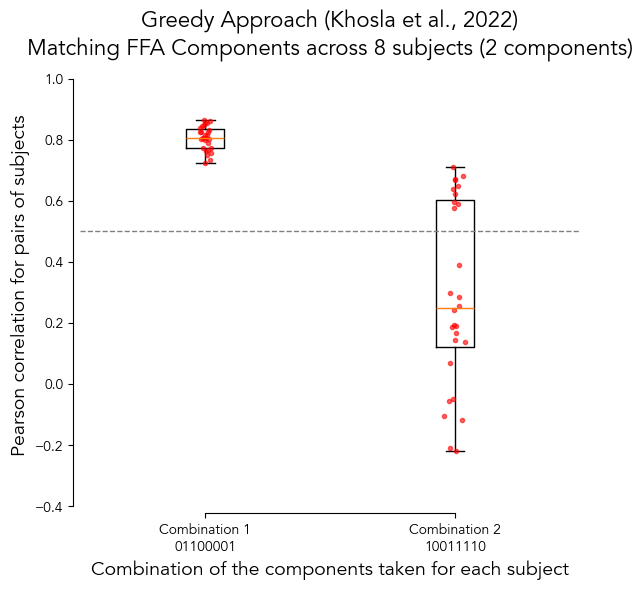

In [126]:
# Greedy approach to find the two components with highest inter-subject consistency

# Get the valuues and the combinations with the highest average correlation
best_ffa_combination = ffa_component_corrs_df.iloc[0]
final_component_1_combination = best_ffa_combination[[f'subject_{subj}_comp_idx' for subj in subjects]].values
final_component_1_corrs = best_ffa_combination['corr_values']

# Flip the components to get the second component
final_component_2_combination = [(idx + 1) % N_components_ffa for idx in final_component_1_combination]
# Get the correlation values for the second component combination
second_best_ffa_combination = ffa_component_corrs_df[
    (ffa_component_corrs_df[[f'subject_{subj}_comp_idx' for subj in subjects]] == final_component_2_combination).all(axis=1)
]
if len(second_best_ffa_combination) > 1:
    print("Warning: More than one combination found for the second best component. Taking the first one.")
    final_component_2_corrs = second_best_ffa_combination.iloc[0]['corr_values']
elif len(second_best_ffa_combination) > 0:
    final_component_2_corrs = second_best_ffa_combination.iloc[0]['corr_values']
else:
    final_component_2_corrs = None

# Make a box plot of the correlation values for the two components (mark the median for the boxplot)
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
assert final_component_2_corrs is not None
box_data = [final_component_1_corrs, final_component_2_corrs]
box_labels = [
    'Combination 1\n' + ''.join([str(idx) for idx in final_component_1_combination]),
    'Combination 2\n' + ''.join([str(idx) for idx in final_component_2_combination])
]
# ''.join([str(idx) for idx in final_component_1_combination])
ax.boxplot(box_data, tick_labels=box_labels)
# Also show actual data points with some jitter
for i, y in enumerate(box_data):
    x = np.random.normal(i + 1, 0.02, size=len(y))
    ax.plot(x, y, 'r.', alpha=0.6)
# Make a dashed line at y=0.5
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
ax.set_ylabel('Pearson correlation for pairs of subjects', fontsize=14)
ax.set_xlabel('Combination of the components taken for each subject', fontsize=14)
ax.set_title(f'Greedy Approach (Khosla et al., 2022)\nMatching FFA Components across {N_subjects} subjects ({n_components} components)', fontsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.set_ylim((-0.4, 1.05))
ax.spines['left'].set_bounds(-0.4, 1)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/ffa_component_correlation_boxplot.png', dpi=300)
plt.show()
plt.close()

Total unique combination pairs: 128


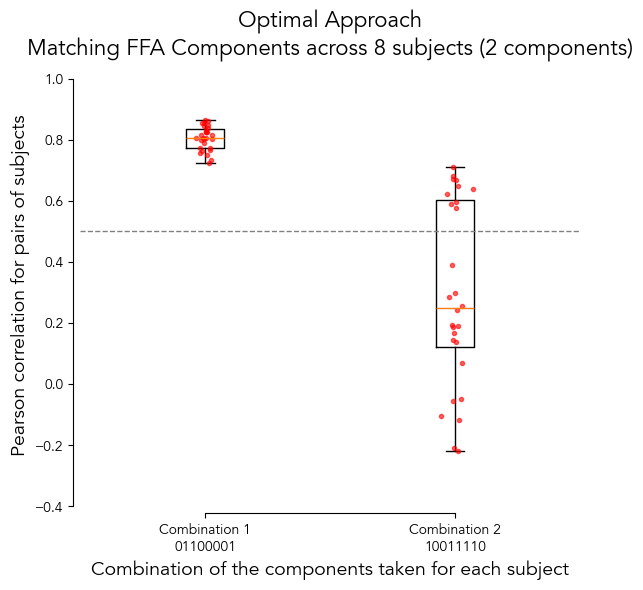

In [ ]:
# Optimal average combination consistency approach to find the two components with highest inter-subject consistency

run_approach2_optimal = False

if run_approach2_optimal:
    # Another approach to find the two component combinations with highest average correlation across the two combinations
    # This approach finds the two combinations that maximize the sum of their average correlations while ensuring they are different
    all_possible_combinations = list(itertools.product(range(n_components), repeat=N_subjects))
    all_possible_combinations = [''.join([str(x) for x in p]) for p in all_possible_combinations]
    all_possible_combination_pairs = []
    # Match up pairs of combinations that are the flipped version of each other, eg - 1010 and 0101
    for comb1 in all_possible_combinations:
        for comb2 in all_possible_combinations:
            if comb1 != comb2 and all((c1 + c2) % 2 == 1 for c1, c2 in zip([int(x) for x in comb1], [int(x) for x in comb2])):
                pair = tuple(sorted([comb1, comb2]))
                if pair not in all_possible_combination_pairs:
                    all_possible_combination_pairs.append(pair)
    print(f"Total unique combination pairs: {len(all_possible_combination_pairs)}")
    # Now make a dataframe with the average correlations for each pair and also the corr values
    combination_pair_df = []
    for comb1, comb2 in all_possible_combination_pairs:
        avg_corr1 = ffa_component_corrs_df[
            (ffa_component_corrs_df[[f'subject_{subj}_comp_idx' for subj in subjects]] == [int(x) for x in comb1]).all(axis=1)
        ]['avg_corr'].values
        avg_corr2 = ffa_component_corrs_df[
            (ffa_component_corrs_df[[f'subject_{subj}_comp_idx' for subj in subjects]] == [int(x) for x in comb2]).all(axis=1)
        ]['avg_corr'].values
        corr_values1 = ffa_component_corrs_df[
            (ffa_component_corrs_df[[f'subject_{subj}_comp_idx' for subj in subjects]] == [int(x) for x in comb1]).all(axis=1)
        ]['corr_values'].values
        corr_values2 = ffa_component_corrs_df[
            (ffa_component_corrs_df[[f'subject_{subj}_comp_idx' for subj in subjects]] == [int(x) for x in comb2]).all(axis=1)
        ]['corr_values'].values
        assert len(avg_corr1) == len(avg_corr2) == len(corr_values1) == len(corr_values2) <= 1
        combination_pair_df.append({
            'combination_1': comb1,
            'combination_2': comb2,
            'avg_corr_1': avg_corr1[0],
            'avg_corr_2': avg_corr2[0],
            'sum_avg_corr': avg_corr1[0] + avg_corr2[0],
            'corr_values_1': corr_values1[0],
            'corr_values_2': corr_values2[0],
        })
    combination_pair_df = pd.DataFrame(combination_pair_df)
    # Sort by sum_avg_corr descending
    combination_pair_df = combination_pair_df.sort_values(by='sum_avg_corr', ascending=False).reset_index(drop=True)
    # Get the top combination pair
    best_combination_pair = combination_pair_df.iloc[0]
    best_combination_1 = best_combination_pair['combination_1']
    best_combination_2 = best_combination_pair['combination_2']
    best_combination_1_corrs = best_combination_pair['corr_values_1']
    best_combination_2_corrs = best_combination_pair['corr_values_2']
    # Make the box plot again
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    box_data = [best_combination_1_corrs, best_combination_2_corrs]
    box_labels = [
        'Combination 1\n' + best_combination_1,
        'Combination 2\n' + best_combination_2
    ]
    ax.boxplot(box_data, tick_labels=box_labels)
    # Also show actual data points with some jitter
    for i, y in enumerate(box_data):
        x = np.random.normal(i + 1, 0.02, size=len(y))
        ax.plot(x, y, 'r.', alpha=0.6)
    # Make a dashed line at y=0.5
    ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
    ax.set_ylabel('Pearson correlation for pairs of subjects', fontsize=14)
    ax.set_xlabel('Combination of the components taken for each subject', fontsize=14)
    ax.set_title(f'Optimal Approach\nMatching FFA Components across {N_subjects} subjects ({n_components} components)', fontsize=16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['bottom'].set_bounds(1, 2)
    ax.set_ylim((-0.4, 1.05))
    ax.spines['left'].set_bounds(-0.4, 1)
    plt.tight_layout()
    # plt.savefig(f'{PLOTS_DIR}/ffa_component_correlation_boxplot_optimal.png', dpi=300)
    plt.show()
    plt.close()

In [ ]:
# Get the final components for each subject based on the greedy approach
# final_component_1_combination = best_ffa_combination[[f'subject_{subj}_comp_idx' for subj in subjects]].values
# final_component_1_corrs = best_ffa_combination['corr_values']
final_components_df = []
for component_idx, (component_combination, component_corrs) in enumerate(zip(
    [final_component_1_combination, final_component_2_combination],
    [final_component_1_corrs, final_component_2_corrs]
)):
    n_samples = None
    subject_component_data_dict = {} # Store the data for each subject across samples
    for subject_idx, subject_component_idx in enumerate(component_combination):
        subject_component_idx = int(subject_component_idx)
        subject_component_data = subject_consensus_components[subjects[subject_idx]][:, subject_component_idx]
        subject_component_data_dict[subjects[subject_idx]] = subject_component_data
        n_samples = subject_component_data.shape[0]
    for sample_idx in range(n_samples):
        sample_dict = {
            'sample_idx': sample_idx,
            'component_idx': component_idx,
            'combination': ''.join([str(idx) for idx in component_combination]),
        }
        for subject_num, subject_data in subject_component_data_dict.items():
            sample_dict[f'subject_{subject_num}'] = subject_data[sample_idx]
        sample_dict['intersubject_corrs_median'] = np.median(component_corrs)
        sample_dict['intersubject_corrs_sem'] = np.std(component_corrs) / np.sqrt(len(component_corrs))
        sample_dict['intersubject_corrs_all'] = component_corrs
        final_components_df.append(sample_dict)
final_components_df = pd.DataFrame(final_components_df)

[np.int64(0) np.int64(1) np.int64(1) np.int64(0) np.int64(0) np.int64(0)
 np.int64(0) np.int64(1)]
[np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(0)]


In [144]:
# Save the data

# Save individual NMF runs as npz
np.savez(
    f"{results_dir}/nmf_individual_runs_subjects_ncomponents.npz",
    **{str(k): v for k, v in subjects_nmf_decomposed.items()}
)

# Save consensus components as npz
np.savez(f"{results_dir}/nmf_consensus_components_subjects_{N_components_ffa}_components.npz", 
         **{str(k): v for k, v in subject_consensus_components.items()})

# Save stabilities as json
with open(f"{results_dir}/nmf_consensus_stabilities_subjects_{N_components_ffa}_components.json", 'w') as f:
    json.dump(subject_consensus_stabilities, f)

# Save the combination correlation dataframes as csv
ffa_component_corrs_df.to_csv(f"{results_dir}/component_combination_subjsbj_correlation.csv", index=False)

# Save the final components dataframe as csv
final_components_df.to_csv(f"{results_dir}/final_component_combinations_{N_components_ffa}_components.csv", index=False)

In [145]:
# Get model data

# Get subject data
_, images_df = nsd.get_betas(
    NSD_DIR, subject, froi, tthreshold, voxels=True, subset=515
)
# Add COCO labels to images_df
images_df = add_image_info_to_df(images_df)
# Get stimuli
nsdcoco_stim = nsd.get_stimuli_dataset(
    NSD_DIR, transform=None, subset=515
).all_stimuli
stimuli = torch.tensor(nsdcoco_stim)
# Get model data
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, froi_localizer='grillspector',
    froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, subset=515
)

# Expected shapes
# model_data: (num_images, num_features)
# stimuli: (num_images, height, width, channels)
print("Model data shape:", model_data.shape)
print("Stimuli shape:", stimuli.shape)

n_samples = subject_data.shape[0]
print("Number of samples:", n_samples)

Model data shape: torch.Size([515, 729])
Stimuli shape: torch.Size([515, 425, 425, 3])
Number of samples: 515


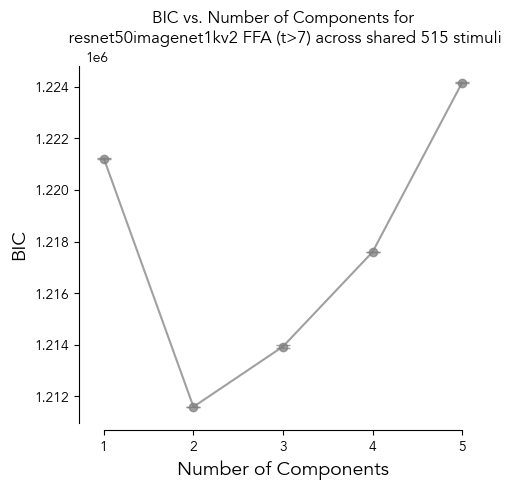

In [ ]:
# Find optimal number of components for model data
n_components_list = [1, 2, 3, 4, 5]
# model_nmf_decomposed = {}
# for n_components in n_components_list:
#     print(f"Running NMF for model data with {n_components} components...")
#     if n_components not in model_nmf_decomposed:
#         model_nmf_decomposed[n_components] = {
#             'H_dict': None,
#             'W_dict': None,
#             'metrics_df_dict': None
#         }
#     nmf_W, nmf_H, nmf_metrics_df = get_nmf_decomposed_data(model_data.cpu().numpy(), n_components=n_components)
#     model_nmf_decomposed[n_components]['H_dict'] = nmf_H
#     model_nmf_decomposed[n_components]['W_dict'] = nmf_W
#     model_nmf_decomposed[n_components]['metrics_df_dict'] = nmf_metrics_df

# Loading the processed dict
model_results_dir = f'{results_dir}/{model.name}'
model_nmf_decomposed = dict(np.load(f"{model_results_dir}/nmf_individual_runs_model_ncomponents.npz", allow_pickle=True))
model_nmf_decomposed = {int(k): v.item() for k, v in model_nmf_decomposed.items()}

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
model_component_bics = []
for n_components in n_components_list:
    metrics_df = model_nmf_decomposed[n_components]['metrics_df_dict']
    model_component_bics.append(metrics_df['bic'].tolist())
# Plot a bix plot of the BICs for each n_components across subjects
model_component_bic_medians = np.array([np.median(bics) for bics in model_component_bics])
model_component_bic_sems = np.array(
    [np.std(bics) / np.sqrt(len(bics)) for bics in model_component_bics]
)
ax.errorbar(
    range(n_components),
    model_component_bic_medians,
    yerr=model_component_bic_sems,
    capsize=5,
    fmt='o-', color='gray', alpha=0.75, zorder=2
)
ax.set_xlabel('Number of Components', fontsize=14)
ax.set_ylabel('BIC', fontsize=14)
ax.set_title(f'BIC vs. Number of Components for\n {model.name} {froi} (t>{tthreshold}) across shared 515 stimuli', fontsize=12)
# ax.set_ylim((-0.05, 1.05))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(min(n_components_list)-1, max(n_components_list)-1)
# ax.spines['left'].set_bounds(0, 1)
ax.set_xticks((np.array(n_components_list) - 1), n_components_list)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/nmf_bic_all_subjects_{froi}.png', dpi=300)
plt.show()
plt.close()

In [ ]:
# Get consensus components for model data for n_components=2
N_components_model = 2
n_components = N_components_model
model_consensus_components = None
model_consensus_stability = None
nmf_H_dict = model_nmf_decomposed[n_components]['H_dict']
consensus_H, stability = get_nmf_consensus_components(nmf_H_dict)
model_consensus_components = consensus_H
model_consensus_stability = stability
print(f"Model consensus stability: {stability}")

Model consensus stability: 0.8966190735242122


In [178]:
# Correlation between model and subject components
subject_components_final = final_components_df[final_components_df['component_idx'] == 0].copy()
model_components_final = pd.DataFrame(model_consensus_components, columns=[f'model_component_{i+1}' for i in range(N_components_model)])
model_components_final['sample_idx'] = range(model_components_final.shape[0])
# Merge the two dataframes on sample_idx
merged_model_subjects_components_df = pd.merge(
    subject_components_final,
    model_components_final,
    on='sample_idx',
    suffixes=('_subject', '_model')
)
n_subjects = len(subjects)

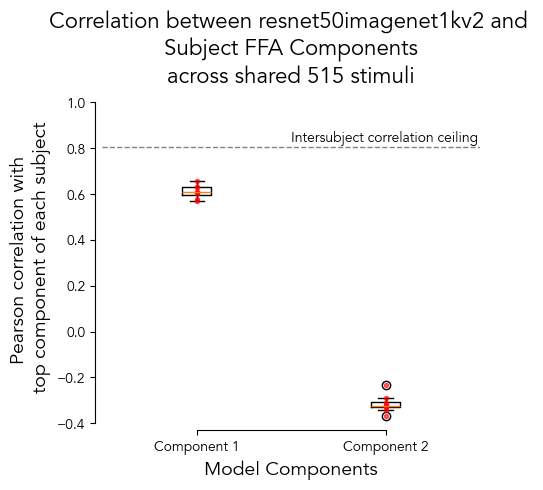

In [212]:
# make a boxplot of the correlation between each model component with each subject component
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
box_data = []
box_labels = []
for model_comp_idx in range(N_components_model):
    model_comp_name = f'model_component_{model_comp_idx + 1}'
    model_comp_corrs = []
    for subject_idx in range(n_subjects):
        subject_comp_name = f'subject_{subject_idx+1}'
        # Compute the correlation between the model component and the subject component across samples
        corr_value = merged_model_subjects_components_df[[model_comp_name, subject_comp_name]].corr().iloc[0, 1]
        model_comp_corrs.append(corr_value)
    box_data.append(model_comp_corrs)
    box_labels.append(f'Component {model_comp_idx + 1}')
box_data = np.array(box_data)
ax.boxplot(box_data.T, tick_labels=box_labels)
# Also show actual data points with some jitter
ax.plot(np.arange(1, len(box_data) + 1), box_data, 'r.', alpha=0.6)

# Plot the ceiling
ceiling = merged_model_subjects_components_df.iloc[0]['intersubject_corrs_median']
ax.axhline(ceiling, color='gray', linestyle='--', linewidth=1)
# Write text for labelling
ax.text(1.5, ceiling + 0.02, f'Intersubject correlation ceiling', color='k', fontsize=10)

ax.set_xlabel(f'Model Components', fontsize=14)
ax.set_ylabel('Pearson correlation with \ntop component of each subject', fontsize=14)
ax.set_title(f'Correlation between {model.name} and \nSubject FFA Components\nacross shared 515 stimuli', fontsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, len(box_data))
ax.set_ylim((-0.4, 1.05))
ax.spines['left'].set_bounds(-0.4, 1)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_subject_component_correlation_boxplot.png', dpi=300)
plt.show()
plt.close()

In [ ]:
# Save the model data

model_results_dir = f'{results_dir}/{model.name}'
os.makedirs(model_results_dir, exist_ok=True)

np.savez(
    f"{model_results_dir}/nmf_individual_runs_model_ncomponents.npz",
    **{str(k): v for k, v in model_nmf_decomposed.items()}
)

np.savez(f"{model_results_dir}/nmf_consensus_components_model_{N_components_model}_components.npz", 
         model_consensus_components)

# Save stability as json
with open(f"{model_results_dir}/nmf_consensus_stability_model_{N_components_model}_components.json", 'w') as f:
    json.dump({'stability': model_consensus_stability}, f)

# Save the final merged csv
merged_model_subjects_components_df.to_csv(f"{model_results_dir}/{froi}_model_subjects_component_correlations.csv", index=False)

/tmp/ipykernel_3908558/3643949056.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subject_median_component_data['median_across_subjects'] = subject_median_component_data[[f'subject_{i+1}' for i in range(len(subjects))]].median(axis=1)


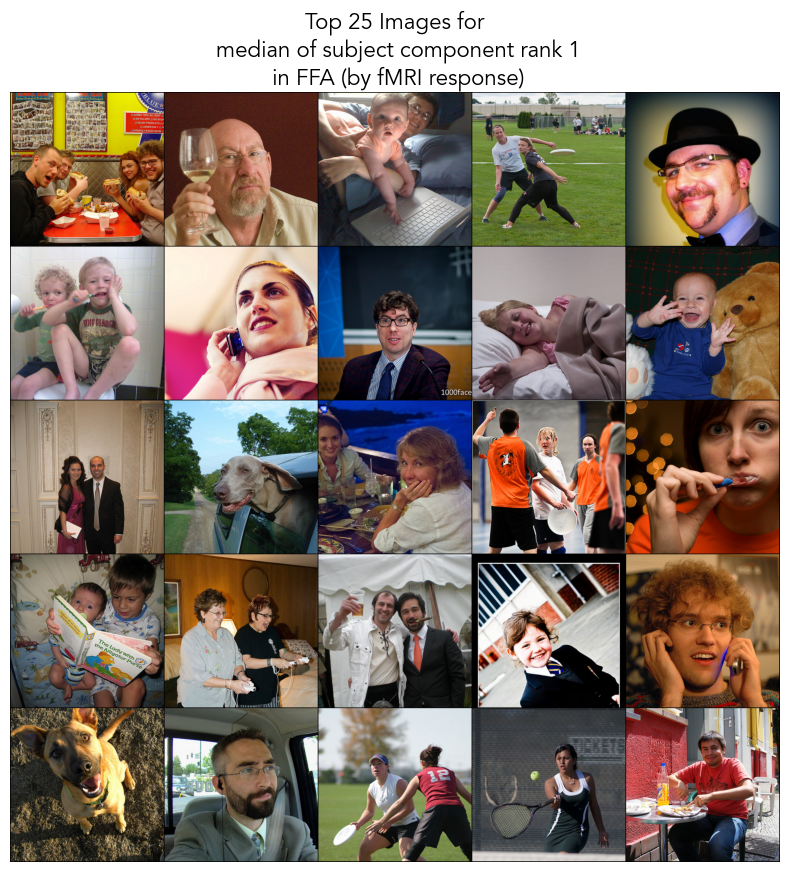

/tmp/ipykernel_3908558/3643949056.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subject_median_component_data['median_across_subjects'] = subject_median_component_data[[f'subject_{i+1}' for i in range(len(subjects))]].median(axis=1)


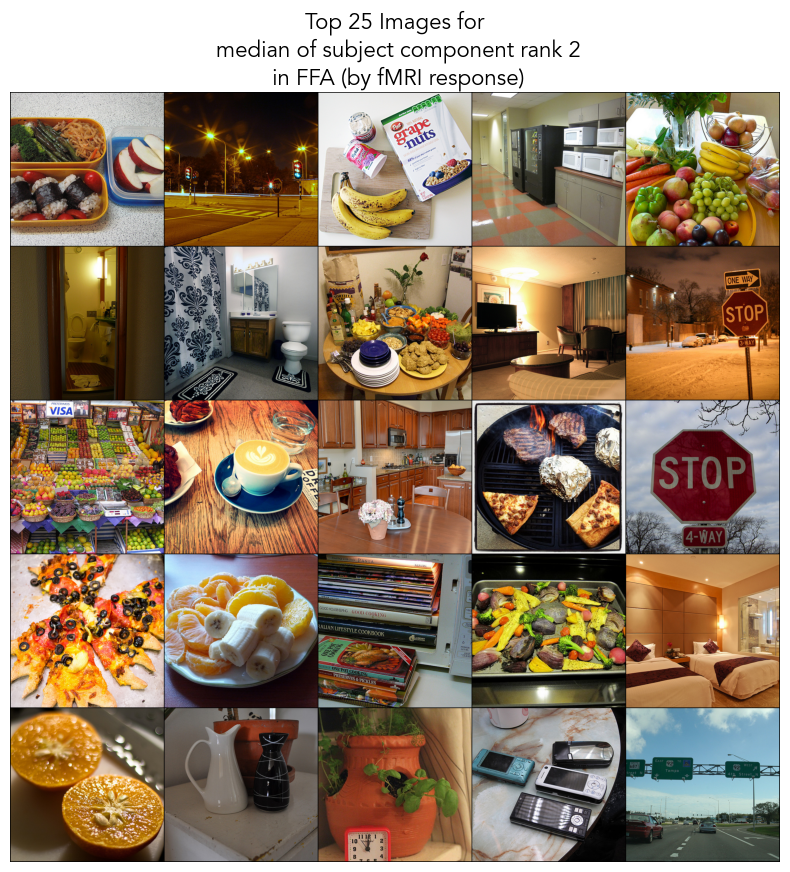

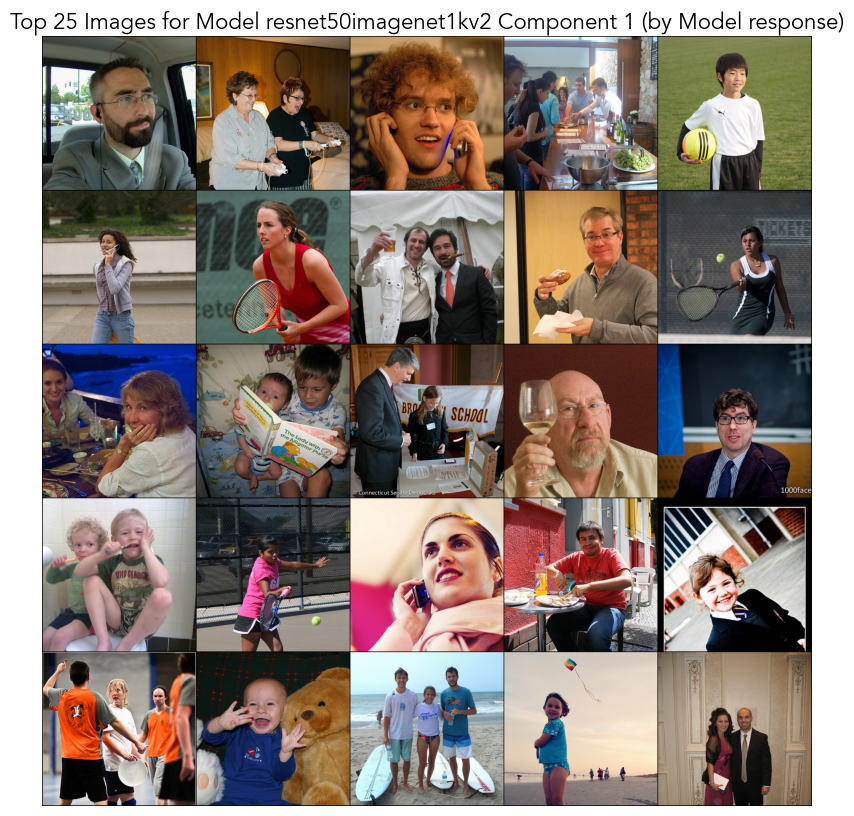

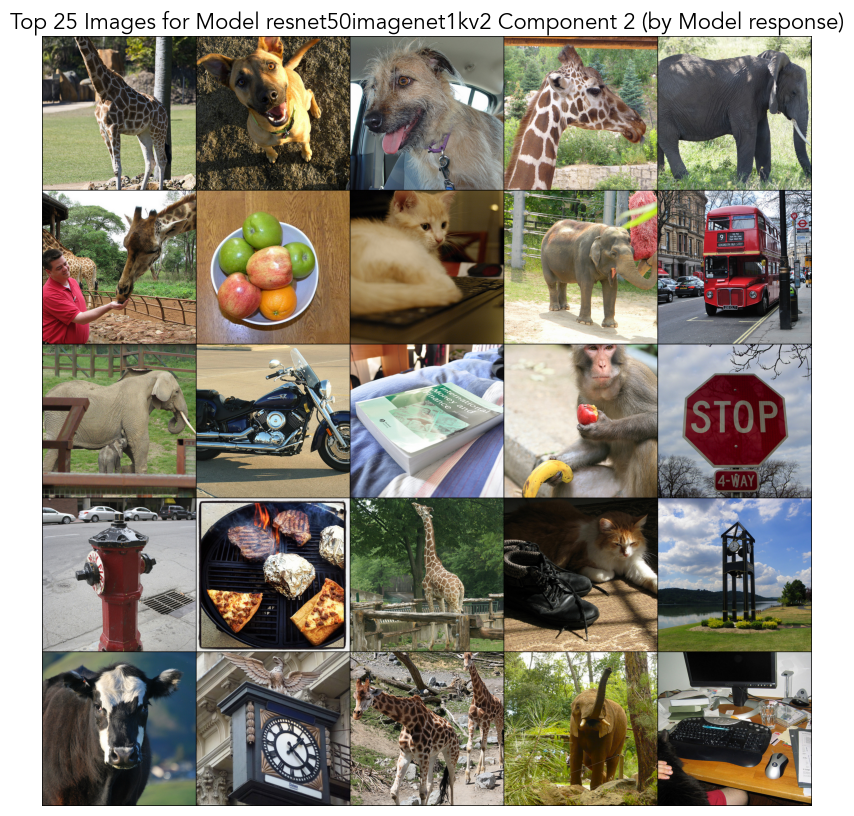

In [209]:
# plot top 25 images for each component for model and median across subjects
n_top = 25

for i in range(N_components_ffa):
    subject_median_component_data = final_components_df[final_components_df['component_idx'] == i]
    # Take median across subject columns
    subject_median_component_data['median_across_subjects'] = subject_median_component_data[[f'subject_{i+1}' for i in range(len(subjects))]].median(axis=1)
    subject_median_component_data = subject_median_component_data.sort_values(by='median_across_subjects', ascending=False).reset_index(drop=True)
    subject_median_component_data = subject_median_component_data.head(n_top)
    topn_subject_indices = subject_median_component_data['sample_idx'].values
    # Plot the top 25 images for the subject using torchvision grid
    # Subject top 25
    topn_subject_images = stimuli[topn_subject_indices]
    topn_subject_images_tensor = topn_subject_images.permute(0, 3, 1, 2).float() # Convert to (N, C, H, W)
    grid_subject = vutils.make_grid(topn_subject_images_tensor, nrow=5, padding=2, normalize=True)
    plt.figure(figsize=(10, 10))
    plt.imshow(grid_subject.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
    plt.axis('off')
    plt.title(f'Top {n_top} Images for\n median of subject component rank {i+1}\n in {froi} (by fMRI response)', fontsize=16)
    plt.show()

topn_model_indices = []
for i in range(N_components_model):
    model_component_data = model_consensus_components[:, i]
    n_samples = model_component_data.shape[0]
    topn_model_idx = np.argsort(model_component_data)[n_samples-n_top:]
    topn_model_idx = topn_model_idx[::-1].copy()
    topn_model_indices.append(topn_model_idx)

# Model top 25 for each component
for i, topn_model_idx in enumerate(topn_model_indices):
    topn_model_images = stimuli[topn_model_idx]
    topn_model_images_tensor = topn_model_images.permute(0, 3, 1, 2).float()  # Convert to (N, C, H, W)
    grid_model = vutils.make_grid(topn_model_images_tensor, nrow=5, padding=2, normalize=True)
    plt.figure(figsize=(10, 10))
    plt.imshow(grid_model.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
    plt.axis('off')
    plt.title(f'Top {n_top} Images for Model {model.name} Component {i+1} (by Model response)', fontsize=16)
    plt.show()
plt.close()

# Plot the top 100 images for the subject using torchvision grid
# Subject top 100
# top100_subject_images = stimuli[top100_subject_indices]
# top100_subject_images_tensor = top100_subject_images.permute(0, 3, 1, 2).float() # Convert to (N, C, H, W)
# grid_subject = vutils.make_grid(top100_subject_images_tensor, nrow=10, padding=2, normalize=True)
# plt.figure(figsize=(15, 15))
# plt.imshow(grid_subject.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
# plt.axis('off')
# plt.title(f'Top 100 Images for Subject {subject} in {froi} (by fMRI response)', fontsize=16)
# plt.show()
# # Model top 100
# top100_model_images = stimuli[top100_model_indices]
# top100_model_images_tensor = top100_model_images.permute(0, 3, 1, 2).float()  # Convert to (N, C, H, W)
# grid_model = vutils.make_grid(top100_model_images_tensor, nrow=10, padding=2, normalize=True)
# plt.figure(figsize=(15, 15))
# plt.imshow(grid_model.permute(1, 2, 0))  # Convert back to (H, W, C) for plotting
# plt.axis('off')
# plt.title(f'Top 100 Images for Model {model_name} Layer {layer} (by Model response)', fontsize=16)
# plt.show()